# Continuous climate

Explore robust scaling, PCA, local edge fields and stability across time; the final R1 section is exploratory visualization.

**Part 3/3 of a shared-state notebook series.** This part uses variables/functions from earlier parts. Opening another notebook normally creates a new kernel. Use `python scripts/run_series.py microstructure --export outputs/microstructure_combined.ipynb` from the repository root, then open the exported notebook for interactive execution. Exporting does not execute the research or restore missing data.

**Status:** curated research source; original saved outputs preserved. Original notes about results are historical observations, not revalidated conclusions. Read `docs/DATA_AND_RUNNING.md` before execution.

Source: `Micro Structure.ipynb`, original cells 431–556 (zero-based).


# Sprint M — Manifold : Continuous Climate

coordinate system สำหรับโลกที่เรามองเห็นจาก data ของเรา

ตลาดไม่ใช่ finite state machine :(

แต่มันอาจจะเป็น continuous dynamical system ;-;

แทนที่จะ:

```text
climate_state ∈ {1,2,3,...}
IF climate == A THEN trade
```

คิดเป็น:

```text
market_favorability ∈ ℝ
final_score = model_score × f(climate_continuous)
```

In [ ]:
import polars as pl

df = pl.read_parquet(str(data_path("Micro Structure Behavior/df_q_fixed_L_to_Tree.parquet")))

## Predict on Predict

In [ ]:
import pandas as pd

PRED_PATHS = [
    str(data_path("Micro Structure Behavior/cat_v1_data/preds_F1.parquet")),
    str(data_path("Micro Structure Behavior/cat_v1_data/preds_F2.parquet")),
    str(data_path("Micro Structure Behavior/cat_v1_data/preds_F3.parquet")),
    str(data_path("Micro Structure Behavior/cat_v1_data/preds_F4.parquet")),
]

preds = pd.concat([pd.read_parquet(p) for p in PRED_PATHS], ignore_index=True)

In [ ]:
preds_pl = pl.from_pandas(preds)

In [ ]:
preds_pl

t,climate_state,y_hit,y_up,p_hit,score,fold
datetime[ms],str,i8,i8,f64,f64,str
2022-01-01 00:00:00,"""0_2_1""",0,0,0.513396,null,"""F1"""
2022-01-01 00:01:00,"""0_2_1""",0,0,0.489537,null,"""F1"""
2022-01-01 00:02:00,"""0_2_1""",0,0,0.481506,null,"""F1"""
2022-01-01 00:03:00,"""0_2_1""",0,0,0.486452,null,"""F1"""
2022-01-01 00:04:00,"""0_2_1""",0,0,0.492615,null,"""F1"""
…,…,…,…,…,…,…
2025-12-31 23:25:00,"""0_3_1""",1,0,0.733841,0.045704,"""F4"""
2025-12-31 23:26:00,"""0_3_1""",0,0,0.760419,null,"""F4"""
2025-12-31 23:27:00,"""0_3_1""",0,0,0.759555,null,"""F4"""


In [ ]:
df = df.join(
    preds_pl,
    on="t",
    how="left"
)

## Manifold v0 เริ่ม 4 แกน

active_ms_rank_ema_480

rv_sqrt_q_rank_ema_480

run_mean_q_rank_ema_480

avg_trade_q_rank_ema_480

In [ ]:
def build_manifold_table(
    df: pl.DataFrame,
    *,
    out_path: str,
    tcol="t",
    missing_col="is_missing_fill",
    x1="active_ms_rank_ema_480",
    x2="rv_sqrt_q_rank_ema_480",
    x3="run_mean_q_rank_ema_480",
    x4="avg_trade_q_rank_ema_480",
    p_hit="p_hit",
    score_dir="score",
) -> pl.DataFrame:

    need = [tcol, missing_col, x1, x2, x3, x4, p_hit, score_dir]
    missing = [c for c in need if c not in df.columns]
    assert not missing, f"Missing columns: {missing}"

    mt = (
        df.select(need)
          .sort(tcol)
          # drop missing fill rows
          .filter(~pl.col(missing_col))
          # drop rows where any manifold axis is null/NaN/inf
          .filter(
              pl.all_horizontal([
                  pl.col(x1).is_not_null() & pl.col(x1).is_finite(),
                  pl.col(x2).is_not_null() & pl.col(x2).is_finite(),
                  pl.col(x3).is_not_null() & pl.col(x3).is_finite(),
                  pl.col(x4).is_not_null() & pl.col(x4).is_finite(),
              ])
          )
          # optional: also ensure p_hit/score_dir are finite (keep if you want strict)
          .filter(
              pl.all_horizontal([
                  pl.col(p_hit).is_not_null() & pl.col(p_hit).is_finite(),
                  pl.col(score_dir).is_not_null() & pl.col(score_dir).is_finite(),
              ])
          )
          .rename({
              x1: "x1_active_ms_rank_ema_480",
              x2: "x2_rv_sqrt_q_rank_ema_480",
              x3: "x3_run_mean_q_rank_ema_480",
              x4: "x4_avg_trade_q_rank_ema_480",
              p_hit: "p_hit",
              score_dir: "score_dir",
          })
    )

    mt.write_parquet(out_path)
    return mt

In [ ]:
out_path = str(data_path("Micro Structure Behavior/cat_v1_data/manifold_table.parquet"))
manifold_table = build_manifold_table(df, out_path=out_path)

print("saved:", out_path)
print(manifold_table.shape)
print(manifold_table.head())

saved: /content/drive/MyDrive/LoserToWinner/Micro Structure Behavior/cat_v1_data/manifold_table.parquet
(550026, 8)
shape: (5, 8)
┌────────────┬────────────┬────────────┬────────────┬───────────┬───────────┬──────────┬───────────┐
│ t          ┆ is_missing ┆ x1_active_ ┆ x2_rv_sqrt ┆ x3_run_me ┆ x4_avg_tr ┆ p_hit    ┆ score_dir │
│ ---        ┆ _fill      ┆ ms_rank_em ┆ _q_rank_em ┆ an_q_rank ┆ ade_q_ran ┆ ---      ┆ ---       │
│ datetime[m ┆ ---        ┆ a_480      ┆ a_480      ┆ _ema_480  ┆ k_ema_480 ┆ f64      ┆ f64       │
│ s]         ┆ bool       ┆ ---        ┆ ---        ┆ ---       ┆ ---       ┆          ┆           │
│            ┆            ┆ f64        ┆ f64        ┆ f64       ┆ f64       ┆          ┆           │
╞════════════╪════════════╪════════════╪════════════╪═══════════╪═══════════╪══════════╪═══════════╡
│ 2022-01-01 ┆ false      ┆ 0.26384    ┆ 0.447322   ┆ 0.469757  ┆ 0.445703  ┆ 0.490943 ┆ 0.018159  │
│ 00:23:00   ┆            ┆            ┆            ┆         

In [ ]:
manifold_table

t,is_missing_fill,x1_active_ms_rank_ema_480,x2_rv_sqrt_q_rank_ema_480,x3_run_mean_q_rank_ema_480,x4_avg_trade_q_rank_ema_480,p_hit,score_dir
datetime[ms],bool,f64,f64,f64,f64,f64,f64
2022-01-01 00:23:00,false,0.26384,0.447322,0.469757,0.445703,0.490943,0.018159
2022-01-01 00:25:00,false,0.261942,0.445658,0.468899,0.444312,0.48572,0.004569
2022-01-01 00:38:00,false,0.25382,0.440379,0.458358,0.446054,0.519784,0.003616
2022-01-01 00:46:00,false,0.260076,0.444709,0.463785,0.444404,0.496628,-0.008766
2022-01-01 00:57:00,false,0.260276,0.451636,0.4622,0.439374,0.481054,0.016343
…,…,…,…,…,…,…,…
2025-12-31 23:17:00,false,0.212645,0.290821,0.41823,0.55589,0.751897,0.03565
2025-12-31 23:18:00,false,0.211844,0.289669,0.417341,0.556855,0.75416,0.020433
2025-12-31 23:19:00,false,0.211005,0.288534,0.41581,0.556323,0.764357,-0.055478


In [ ]:
manifold_table.select([
    pl.col("x4_avg_trade_q_rank_ema_480").min().name.suffix("_min"),
    pl.col("x4_avg_trade_q_rank_ema_480").max().name.suffix("_max"),
])

x4_avg_trade_q_rank_ema_480_min,x4_avg_trade_q_rank_ema_480_max
f64,f64
0.039973,0.952023


In [ ]:
manifold_table.select(pl.col("t").dt.year()).group_by("t").len()

t,len
i32,u32
2023,185162
2022,95922
2025,134460
2024,134482


In [ ]:
manifold_table.select(pl.col("p_hit")).describe()

statistic,p_hit
str,f64
"""count""",550026.0
"""null_count""",0.0
"""mean""",0.581349
"""std""",0.117668
"""min""",0.043411
"""25%""",0.502209
"""50%""",0.579179
"""75%""",0.665894
"""max""",0.898408


In [ ]:
pd.Series(p_hit).describe()

,0
count,630760.000000
mean,0.602516
std,0.133560
min,0.020546
25%,0.516990
50%,0.608567
75%,0.699086
max,0.923387


## Robust Standardization

In [ ]:
X_COLS = [
    "x1_active_ms_rank_ema_480",
    "x2_rv_sqrt_q_rank_ema_480",
    "x3_run_mean_q_rank_ema_480",
    "x4_avg_trade_q_rank_ema_480",
]

# compute medians
med = (
    manifold_table
    .select([pl.col(c).median().alias(c) for c in X_COLS])
    .to_dicts()[0]
)

# compute MAD = median(|x - median|)
mad = (
    manifold_table
    .select([
        (pl.col(c) - med[c]).abs().median().alias(c)
        for c in X_COLS
    ])
    .to_dicts()[0]
)

med, mad

({'x1_active_ms_rank_ema_480': 0.41381230873314356,
  'x2_rv_sqrt_q_rank_ema_480': 0.39816548437853855,
  'x3_run_mean_q_rank_ema_480': 0.4899789866945379,
  'x4_avg_trade_q_rank_ema_480': 0.4528178418748088},
 {'x1_active_ms_rank_ema_480': 0.16330173107306578,
  'x2_rv_sqrt_q_rank_ema_480': 0.14436478938601616,
  'x3_run_mean_q_rank_ema_480': 0.1408420627496497,
  'x4_avg_trade_q_rank_ema_480': 0.10536668255338028})

In [ ]:
manifold_z = manifold_table.with_columns([
    ((pl.col(c) - med[c]) / mad[c]).alias(f"z{i+1}")
    for i, c in enumerate(X_COLS)
])

In [ ]:
manifold_z.select([pl.col(f"z{i}") for i in range(1,5)]).describe()

statistic,z1,z2,z3,z4
str,f64,f64,f64,f64
"""count""",550026.0,550026.0,550026.0,550026.0
"""null_count""",0.0,0.0,0.0,0.0
"""mean""",0.117375,0.103847,0.027055,0.138942
"""std""",1.286372,1.361649,1.333675,1.435668
"""min""",-2.281508,-2.596775,-3.214073,-3.918171
"""25%""",-0.935794,-0.954258,-0.971551,-0.926457
"""50%""",5.2390e-7,0.000003,0.000003,5.3671e-7
"""75%""",1.08508,1.055915,1.030961,1.09888
"""max""",3.478972,4.080866,3.365327,4.73779


In [ ]:
manifold_z.select([pl.col(f"z{i}") for i in range(1,5)]).to_pandas().corr()

,z1,z2,z3,z4
z1,1.000000,0.779334,0.632180,0.175870
z2,0.779334,1.000000,0.658983,0.313936
z3,0.632180,0.658983,1.000000,0.056380
z4,0.175870,0.313936,0.056380,1.000000


In [ ]:
out_path = str(data_path("Micro Structure Behavior/cat_v1_data/manifold_table_z.parquet"))
manifold_z.write_parquet(out_path)

print("saved:", out_path)
print(manifold_z.shape)

saved: /content/drive/MyDrive/LoserToWinner/Micro Structure Behavior/cat_v1_data/manifold_table_z.parquet
(550026, 12)


## Embedding ด้วย PCA

In [ ]:
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA

Z_COLS = ["z1", "z2", "z3", "z4"]

Z = manifold_z.select(Z_COLS).to_pandas().to_numpy(dtype=float)

In [ ]:
assert np.all(np.isfinite(Z)), "Z has non-finite values"

In [ ]:
pca = PCA(n_components=4, random_state=42)
PC = pca.fit_transform(Z)

evr = pca.explained_variance_ratio_
print("Explained variance ratio:", evr)
print("Cumulative:", evr.sum())

Explained variance ratio: [0.59440445 0.2682806  0.08860787 0.04870708]
Cumulative: 1.0


In [ ]:
features = ["active_ms", "rv", "run_mean", "avg_trade_q"]

loadings = pd.DataFrame(
    pca.components_,
    columns=features,
    index=[f"PC{i+1}" for i in range(pca.n_components_)]
)

loadings

,active_ms,rv,run_mean,avg_trade_q
PC1,0.543464,0.605893,0.518570,0.261964
PC2,-0.144229,-0.004884,-0.316723,0.937476
PC3,-0.518550,-0.285872,0.784600,0.183807
PC4,-0.644167,0.742393,-0.123183,-0.136853


In [ ]:
pca = PCA(n_components=2, random_state=42)
PC = pca.fit_transform(Z)

evr = pca.explained_variance_ratio_
print("Explained variance ratio:", evr)
print("Cumulative:", evr.sum())

Explained variance ratio: [0.59440445 0.2682806 ]
Cumulative: 0.8626850534692956


In [ ]:
manifold_pca = (
    manifold_z
    .with_columns([
        pl.Series("pc1", PC[:, 0]),
        pl.Series("pc2", PC[:, 1]),
        pl.Series("pc3", PC[:, 2])
    ])
    .select([
        "t",
        "pc1",
        "pc2",
        "pc3",
        "p_hit",
        "score_dir",
    ])
)

In [ ]:
manifold_pca

t,pc1,pc2,pc3,p_hit,score_dir
datetime[ms],f64,f64,f64,f64,f64
2022-01-01 00:23:00,-0.562079,0.008714,0.297605,0.490943,0.018159
2022-01-01 00:25:00,-0.581994,4.0668e-7,0.299722,0.48572,0.004569
2022-01-01 00:38:00,-0.665661,0.046559,0.280283,0.519784,0.003616
2022-01-01 00:46:00,-0.610791,0.014003,0.279197,0.496628,-0.008766
2022-01-01 00:57:00,-0.599392,-0.027603,0.247242,0.481054,0.016343
…,…,…,…,…,…
2025-12-31 23:17:00,-1.305052,1.15546,0.675248,0.751897,0.03565
2025-12-31 23:18:00,-1.313424,1.166798,0.6768,0.75416,0.020433
2025-12-31 23:19:00,-1.327938,1.166286,0.672259,0.764357,-0.055478


In [ ]:
out_path = str(data_path("Micro Structure Behavior/cat_v1_data/manifold_pca_2d.parquet"))
manifold_pca.write_parquet(out_path)

print("saved:", out_path)
print(manifold_pca.shape)

saved: /content/drive/MyDrive/LoserToWinner/Micro Structure Behavior/cat_v1_data/manifold_pca_2d.parquet
(550026, 5)


## Heatmap-based Edge Field (for visualization)

In [ ]:
import numpy as np
import polars as pl

# parameters
NBINS = 50
MIN_CELL = 200

# ranges
pc1_min, pc1_max = (
    manifold_pca
    .select([
        pl.col("pc1").min().alias("pc1_min"),
        pl.col("pc1").max().alias("pc1_max"),
    ])
    .row(0)
)

pc2_min, pc2_max = (
    manifold_pca
    .select([
        pl.col("pc2").min().alias("pc2_min"),
        pl.col("pc2").max().alias("pc2_max"),
    ])
    .row(0)
)

# assign grid ids
mp_grid = manifold_pca.with_columns([
    (((pl.col("pc1") - pc1_min) / (pc1_max - pc1_min)) * NBINS)
        .floor().clip(0, NBINS - 1).cast(pl.Int16).alias("i"),
    (((pl.col("pc2") - pc2_min) / (pc2_max - pc2_min)) * NBINS)
        .floor().clip(0, NBINS - 1).cast(pl.Int16).alias("j"),
])

In [ ]:
heatmap = (
    mp_grid
    .group_by(["i", "j"])
    .agg([
        pl.len().alias("n_cell"),
        pl.col("p_hit").mean().alias("mean_p_hit"),
        pl.col("score_dir").mean().alias("mean_score_dir"),
        pl.col("score_dir").abs().mean().alias("mean_abs_score_dir"),
        pl.col("pc1").mean().alias("pc1_center"),
        pl.col("pc2").mean().alias("pc2_center"),
    ])
    .filter(pl.col("n_cell") >= MIN_CELL)
)

In [ ]:
out_csv = str(data_path("Micro Structure Behavior/cat_v1_data/heatmap_table.csv"))
heatmap.write_csv(out_csv)

print("saved:", out_csv)
print("cells kept:", heatmap.height)

saved: /content/drive/MyDrive/LoserToWinner/Micro Structure Behavior/cat_v1_data/heatmap_table.csv
cells kept: 881


In [ ]:
heatmap

i,j,n_cell,mean_p_hit,mean_score_dir,mean_abs_score_dir,pc1_center,pc2_center
i16,i16,u32,f64,f64,f64,f64,f64
25,25,725,0.569552,-0.000328,0.026916,0.802073,0.161658
22,18,1136,0.596229,0.002226,0.032436,0.128884,-1.102747
34,12,210,0.506812,0.010692,0.037224,2.810889,-2.197208
30,19,709,0.522987,-0.005708,0.031225,1.926856,-0.921336
25,33,612,0.54841,-0.009434,0.033594,0.810109,1.627217
…,…,…,…,…,…,…,…
8,17,563,0.688594,-0.003101,0.019486,-3.018879,-1.278694
14,22,855,0.644226,0.003449,0.029319,-1.654179,-0.365079
25,11,219,0.614197,0.011099,0.029722,0.815147,-2.359089


## Pointwise kNN-smoothed Edge Field

In [ ]:
from sklearn.neighbors import NearestNeighbors

K = 500

X_pc = manifold_pca.select(["pc1", "pc2", "pc3"]).to_pandas().to_numpy(dtype=float)
p_hit = manifold_pca["p_hit"].to_numpy()
score = manifold_pca["score_dir"].to_numpy()

In [ ]:
nbrs = NearestNeighbors(n_neighbors=K, algorithm="ball_tree", n_jobs=-1)
nbrs.fit(X_pc)

NearestNeighbors(algorithm='ball_tree', n_jobs=-1, n_neighbors=500)

In [ ]:
dist, idx = nbrs.kneighbors(X_pc, return_distance=True)

In [ ]:
p_hit_local = p_hit[idx].mean(axis=1)
score_local = score[idx].mean(axis=1)

In [ ]:
manifold_knn = manifold_pca.with_columns([
    pl.Series("p_hit_local", p_hit_local),
    pl.Series("score_local", score_local),
])

# out_parquet = "/content/drive/MyDrive/LoserToWinner/Micro Structure Behavior/cat_v1_data/pointwise_knn_smoothed.parquet"
# manifold_knn.write_parquet(out_parquet)

# print("saved:", out_parquet)
# print(manifold_knn.shape)

In [ ]:
manifold_knn

t,pc1,pc2,pc3,p_hit,score_dir,p_hit_local,score_local
datetime[ms],f64,f64,f64,f64,f64,f64,f64
2022-01-01 00:23:00,-0.562079,0.008714,0.297605,0.490943,0.018159,0.614703,-0.008971
2022-01-01 00:25:00,-0.581994,4.0668e-7,0.299722,0.48572,0.004569,0.616921,-0.007352
2022-01-01 00:38:00,-0.665661,0.046559,0.280283,0.519784,0.003616,0.615771,-0.007337
2022-01-01 00:46:00,-0.610791,0.014003,0.279197,0.496628,-0.008766,0.617943,-0.007072
2022-01-01 00:57:00,-0.599392,-0.027603,0.247242,0.481054,0.016343,0.616222,-0.004882
…,…,…,…,…,…,…,…
2025-12-31 23:17:00,-1.305052,1.15546,0.675248,0.751897,0.03565,0.630697,-0.009735
2025-12-31 23:18:00,-1.313424,1.166798,0.6768,0.75416,0.020433,0.633632,-0.008985
2025-12-31 23:19:00,-1.327938,1.166286,0.672259,0.764357,-0.055478,0.634324,-0.009399


## Visualization

#### heat

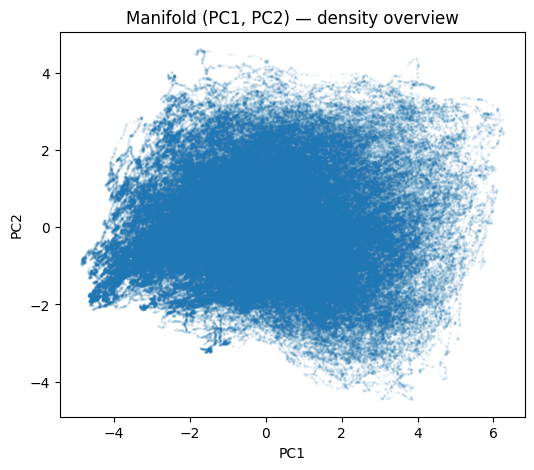

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,5))
plt.scatter(
    manifold_pca["pc1"],
    manifold_pca["pc2"],
    s=1, alpha=0.05
)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Manifold (PC1, PC2) — density overview")
plt.show()

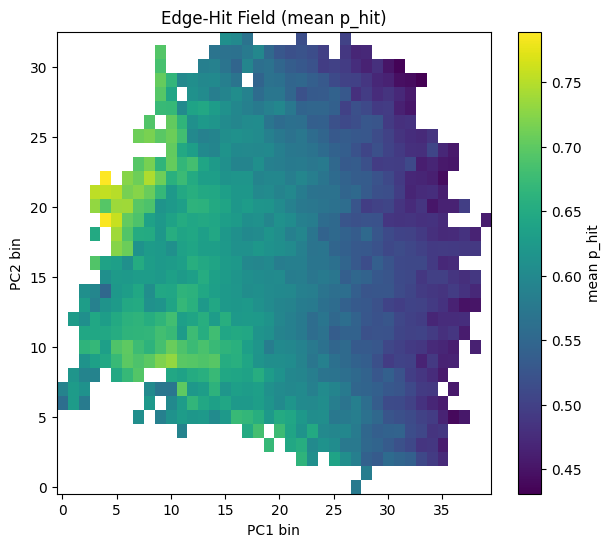

In [ ]:
import pandas as pd
import numpy as np

hm = pd.read_csv(
    str(data_path("Micro Structure Behavior/cat_v1_data/heatmap_table.csv"))
)

# pivot เป็น grid
pivot_hit = hm.pivot(index="j", columns="i", values="mean_p_hit")

plt.figure(figsize=(7,6))
plt.imshow(
    pivot_hit,
    origin="lower",
    aspect="auto",
    cmap="viridis"
)
plt.colorbar(label="mean p_hit")
plt.title("Edge-Hit Field (mean p_hit)")
plt.xlabel("PC1 bin")
plt.ylabel("PC2 bin")
plt.show()

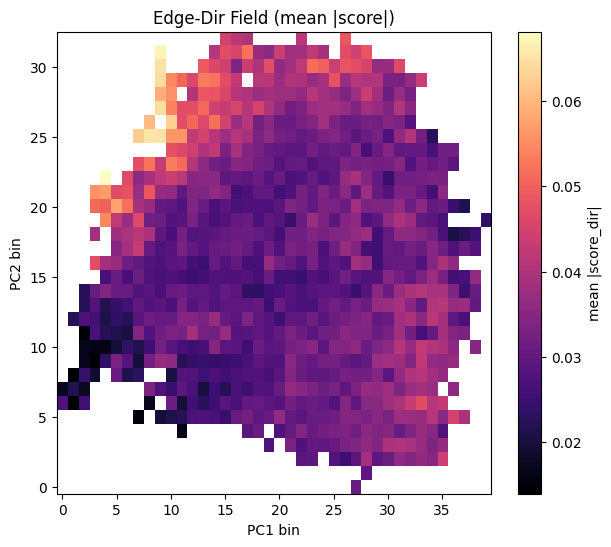

In [ ]:
pivot_dir = hm.pivot(index="j", columns="i", values="mean_abs_score_dir")

plt.figure(figsize=(7,6))
plt.imshow(
    pivot_dir,
    origin="lower",
    aspect="auto",
    cmap="magma"
)
plt.colorbar(label="mean |score_dir|")
plt.title("Edge-Dir Field (mean |score|)")
plt.xlabel("PC1 bin")
plt.ylabel("PC2 bin")
plt.show()

#### knn

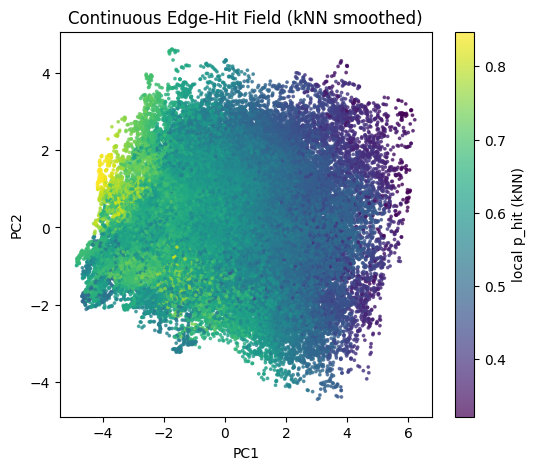

In [ ]:
# subsample เพื่อ plot (ถ้า plot ทั้ง 550k จะหนัก)
sample = manifold_knn.sample(n=80_000, with_replacement=False, seed=42)

plt.figure(figsize=(6,5))
sc = plt.scatter(
    sample["pc1"],
    sample["pc2"],
    c=sample["p_hit_local"],
    s=3,
    cmap="viridis",
    alpha=0.7
)
plt.colorbar(sc, label="local p_hit (kNN)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Continuous Edge-Hit Field (kNN smoothed)")
plt.show()

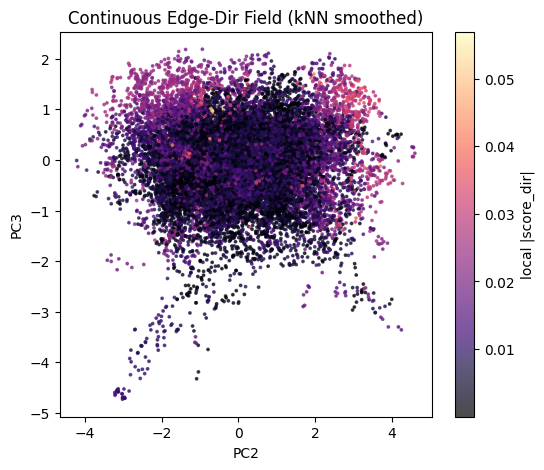

In [ ]:
plt.figure(figsize=(6,5))
sc = plt.scatter(
    sample["pc2"],
    sample["pc3"],
    c=np.abs(sample["score_local"]),
    s=3,
    cmap="magma",
    alpha=0.7
)
plt.colorbar(sc, label="local |score_dir|")
plt.xlabel("PC2")
plt.ylabel("PC3")
plt.title("Continuous Edge-Dir Field (kNN smoothed)")
plt.show()

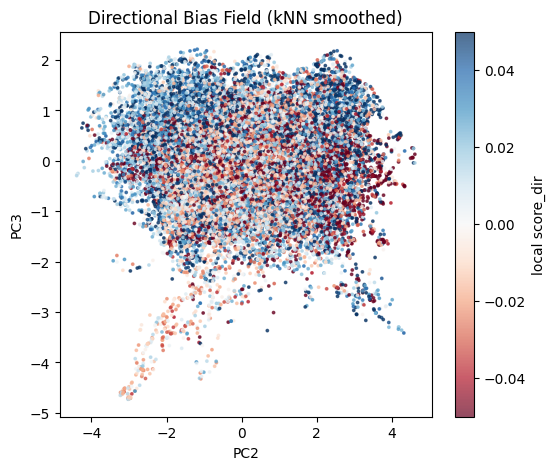

In [ ]:
plt.figure(figsize=(6,5))
sc = plt.scatter(
    sample["pc2"],
    sample["pc3"],
    c=sample["score_dir"],
    s=3,
    cmap="RdBu",
    vmin=-0.05, vmax=0.05,
    alpha=0.7
)
plt.colorbar(sc, label="local score_dir")
plt.xlabel("PC2")
plt.ylabel("PC3")
plt.title("Directional Bias Field (kNN smoothed)")
plt.show()

#### PCA3D

In [ ]:
import pandas as pd
import numpy as np

df3d = manifold_knn.to_pandas()

# drop NaN score (สำคัญ)
df3d = df3d.dropna(subset=["p_hit_local", "pc3"])

# PC3 deciles
df3d["pc3_decile"] = pd.qcut(df3d["pc3"], 10, labels=False)

summary = (
    df3d.groupby("pc3_decile")
      .agg(
          n=("p_hit_local", "size"),
          mean_abs_score=("p_hit_local", lambda x: np.mean(np.abs(x))),
          # mean_score=("score_local", "mean"),
          # p_positive=("score_local", lambda x: np.mean(x > 0)),
      )
)

In [ ]:
summary

,n,mean_abs_score
pc3_decile,,
0,55003,0.528973
1,55003,0.572311
2,55002,0.573788
3,55003,0.578496
4,55002,0.584607
5,55003,0.586226
6,55002,0.588332
7,55003,0.597457
8,55002,0.602947


In [ ]:
summary

,n,mean_abs_score,mean_score,p_positive
pc2_decile,,,,
0,55003,0.012747,0.007953,0.706525
1,55003,0.010011,0.001777,0.552406
2,55002,0.009458,-0.000169,0.428966
3,55003,0.008216,-0.001875,0.350490
4,55002,0.007635,-0.003248,0.284644
5,55003,0.007617,-0.004578,0.224061
6,55002,0.007684,-0.004871,0.238628
7,55003,0.006731,-0.003602,0.290021
8,55002,0.007537,-0.002398,0.383641


In [ ]:
summary

,n,mean_abs_score,mean_score,p_positive
pc3_decile,,,,
0,55003,0.007531,-0.001682,0.431667
1,55003,0.007322,-0.003439,0.342890
2,55002,0.008143,-0.005490,0.259972
3,55003,0.008949,-0.006761,0.219297
4,55002,0.008570,-0.005848,0.211247
5,55003,0.008798,-0.005601,0.211679
6,55002,0.008069,-0.003191,0.291171
7,55003,0.007851,0.000729,0.462338
8,55002,0.010580,0.006566,0.671994


In [ ]:
from scipy.stats import spearmanr

rho_abs, p_abs = spearmanr(df3d["pc3"], np.abs(df3d["score_local"]))
rho_sign, p_sign = spearmanr(df3d["pc3"], df3d["score_local"])

print("Spearman(pc3, |score|):", rho_abs, "p =", p_abs)
print("Spearman(pc3, score): ", rho_sign, "p =", p_sign)

Spearman(pc3, |score|): 0.201652432564207 p = 0.0
Spearman(pc3, score):  0.3290946856840907 p = 0.0


In [ ]:
import plotly.graph_objects as go

sample = manifold_knn.sample(n=20000, seed=42)

# convert to pandas
pdf = sample.to_pandas()

fig = go.Figure(
    data=go.Scatter3d(
        x=pdf["pc1"],
        y=pdf["pc2"],
        z=pdf["pc3"],
        mode="markers",
        marker=dict(
            size=2,
            color=pdf["p_hit_local"],     # <<< key point
            colorscale="Viridis",
            opacity=0.7,
            colorbar=dict(title="local p_hit (kNN)")
        )
    )
)

fig.update_layout(
    title="Continuous Edge-Hit Field (kNN smoothed) in PC Space",
    scene=dict(
        xaxis_title="PC1",
        yaxis_title="PC2",
        zaxis_title="PC3",
    ),
    margin=dict(l=0, r=0, b=0, t=40)
)

fig.show()

In [ ]:
import numpy as np
import plotly.graph_objects as go

# sample: polars DataFrame
sample = manifold_knn.sample(n=50000, seed=42)

pdf = sample.to_pandas()
pdf["abs_score_local"] = np.abs(pdf["score_local"])

fig = go.Figure(
    data=go.Scatter3d(
        x=pdf["pc1"],
        y=pdf["pc2"],
        z=pdf["pc3"],
        mode="markers",
        marker=dict(
            size=2,
            color=pdf["abs_score_local"],   # <<< |score_local|
            colorscale="Magma",
            opacity=0.7,
            colorbar=dict(title="local |score_dir|")
        )
    )
)

fig.update_layout(
    title="Continuous Edge-Dir Field (kNN smoothed) in PC Space",
    scene=dict(
        xaxis_title="PC1",
        yaxis_title="PC2",
        zaxis_title="PC3",
    ),
    margin=dict(l=0, r=0, b=0, t=40)
)

fig.show()

Output hidden; open in https://colab.research.google.com to view.

### local

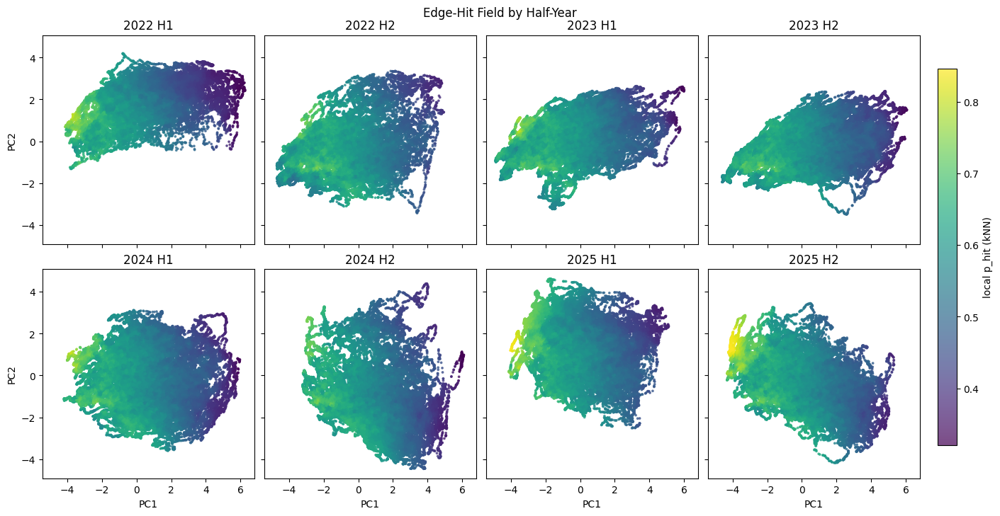

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import polars as pl

# sample และสร้าง half-year label
sample = manifold_knn #.sample(n=80_000, with_replacement=False, seed=42)
sample = sample.with_columns([
    sample["t"].dt.year().alias("year"),
    sample["t"].dt.month().alias("month"),
    (sample["t"].dt.year()*10 + (sample["t"].dt.month() > 6).cast(pl.Int16)).alias("half_id"),
])

# สร้าง label เช่น "2022 H1"
half_ids = sorted(sample["half_id"].unique().to_list())
labels = [f"{h//10} H{(h%10)+1}" for h in half_ids]

vmin = float(sample["p_hit_local"].min())
vmax = float(sample["p_hit_local"].max())

fig, axes = plt.subplots(2, 4, figsize=(14, 7), sharex=True, sharey=True, constrained_layout=True)

for ax, h, lab in zip(axes.ravel(), half_ids, labels):
    sub = sample.filter(pl.col("half_id") == h)
    sc = ax.scatter(
        sub["pc1"], sub["pc2"],
        c=sub["p_hit_local"],
        s=3, alpha=0.7,
        cmap="viridis",
        vmin=vmin, vmax=vmax,
    )
    ax.set_title(lab)

# axis labels
for ax in axes[-1, :]:
    ax.set_xlabel("PC1")
for ax in axes[:, 0]:
    ax.set_ylabel("PC2")

# colorbar ไม่บัง: attach to whole figure
cbar = fig.colorbar(sc, ax=axes.ravel().tolist(), shrink=0.85, pad=0.02)
cbar.set_label("local p_hit (kNN)")

fig.suptitle("Edge-Hit Field by Half-Year", y=1.02)
plt.show()

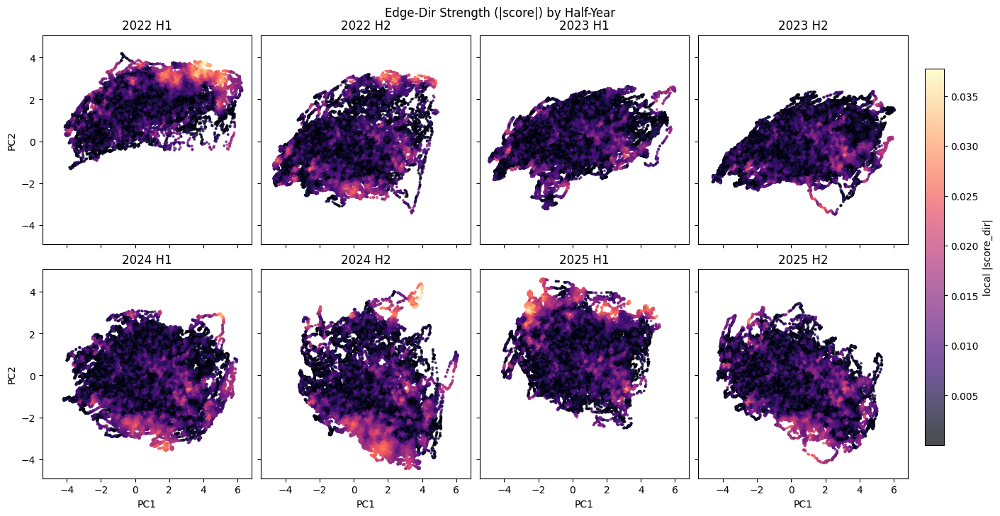

In [ ]:
vmin = float(sample.select(pl.col("score_local").abs().min()).item())
vmax = float(sample.select(pl.col("score_local").abs().max()).item())

fig, axes = plt.subplots(2, 4, figsize=(14, 7), sharex=True, sharey=True, constrained_layout=True)

for ax, h, lab in zip(axes.ravel(), half_ids, labels):
    sub = sample.filter(pl.col("half_id") == h)
    sc = ax.scatter(
        sub["pc1"], sub["pc2"],
        c=sub["score_local"].abs(),
        s=3, alpha=0.7,
        cmap="magma",
        vmin=vmin, vmax=vmax,
    )
    ax.set_title(lab)

for ax in axes[-1, :]:
    ax.set_xlabel("PC1")
for ax in axes[:, 0]:
    ax.set_ylabel("PC2")

cbar = fig.colorbar(sc, ax=axes.ravel().tolist(), shrink=0.85, pad=0.02)
cbar.set_label("local |score_dir|")

fig.suptitle("Edge-Dir Strength (|score|) by Half-Year", y=1.02)
plt.show()

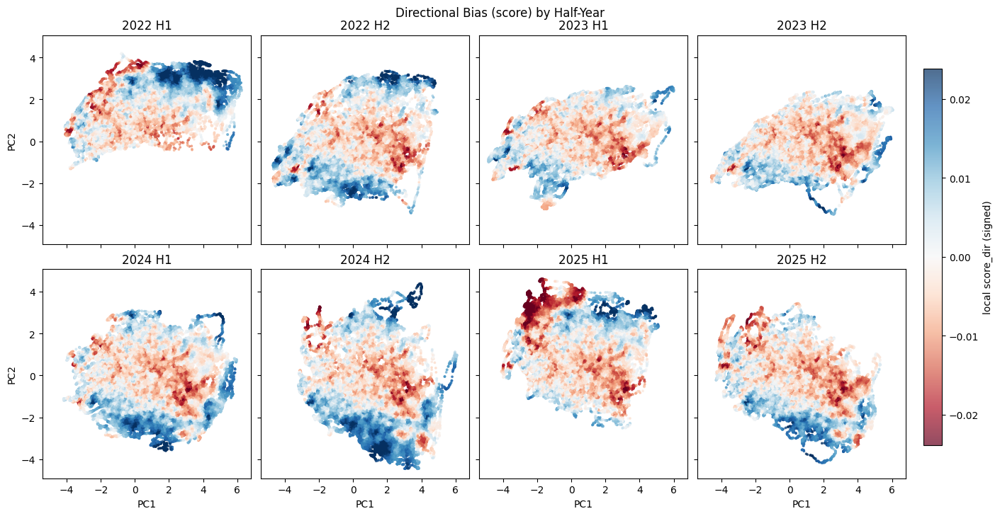

In [ ]:
# symmetric range (robust) ใช้ 99th percentile ของ |score|
abs_q = float(sample.select(pl.col("score_local").abs().quantile(0.99)).item())
vmin, vmax = -abs_q, abs_q

fig, axes = plt.subplots(2, 4, figsize=(14, 7), sharex=True, sharey=True, constrained_layout=True)

for ax, h, lab in zip(axes.ravel(), half_ids, labels):
    sub = sample.filter(pl.col("half_id") == h)
    sc = ax.scatter(
        sub["pc1"], sub["pc2"],
        c=sub["score_local"],
        s=3, alpha=0.7,
        cmap="RdBu",
        vmin=vmin, vmax=vmax,
    )
    ax.set_title(lab)

for ax in axes[-1, :]:
    ax.set_xlabel("PC1")
for ax in axes[:, 0]:
    ax.set_ylabel("PC2")

cbar = fig.colorbar(sc, ax=axes.ravel().tolist(), shrink=0.85, pad=0.02)
cbar.set_label("local score_dir (signed)")

fig.suptitle("Directional Bias (score) by Half-Year", y=1.02)
plt.show()

## Walk-forward PCA + Edge-field stability (Boss)

In [ ]:
import numpy as np
import pandas as pd
import polars as pl
from sklearn.decomposition import PCA

NBINS = 30
MIN_CELL = 200

# FOLDS = [
#     {"fold":"F1", "train_start":"2022-01-01", "train_end":"2022-06-30", "test_start":"2022-07-01", "test_end":"2022-12-31"},
#     {"fold":"F2", "train_start":"2022-01-01", "train_end":"2022-12-31", "test_start":"2023-01-01", "test_end":"2023-12-31"},
#     {"fold":"F3", "train_start":"2022-01-01", "train_end":"2023-12-31", "test_start":"2024-01-01", "test_end":"2024-12-31"},
#     {"fold":"F4", "train_start":"2022-01-01", "train_end":"2024-12-31", "test_start":"2025-01-01", "test_end":"2025-12-31"},
# ]

FOLDS = [
    {"fold":"F1", "train_start":"2022-01-01", "train_end":"2022-12-31", "test_start":"2023-01-01", "test_end":"2023-12-31"},
    {"fold":"F2", "train_start":"2022-01-01", "train_end":"2023-12-31", "test_start":"2024-01-01", "test_end":"2024-12-31"},
    {"fold":"F3", "train_start":"2022-01-01", "train_end":"2024-06-30", "test_start":"2024-07-01", "test_end":"2025-03-31"},
    {"fold":"F4", "train_start":"2022-01-01", "train_end":"2024-12-31", "test_start":"2025-01-01", "test_end":"2025-12-31"},
]

XCOLS = [
    "x1_active_ms_rank_ema_480",
    "x2_rv_sqrt_q_rank_ema_480",
    "x3_run_mean_q_rank_ema_480",
    "x4_avg_trade_q_rank_ema_480",
]

### Helper: year + robust z (median/MAD from train only)

In [ ]:
def add_year(df: pl.DataFrame):
    return df.with_columns(pl.col("t").dt.year().alias("year")).sort("t")

def robust_params_train(train: pl.DataFrame, cols: list[str]):
    med = train.select([pl.col(c).median().alias(c) for c in cols]).to_dicts()[0]
    mad = train.select([(pl.col(c) - med[c]).abs().median().alias(c) for c in cols]).to_dicts()[0]
    eps = 1e-6
    mad = {k: max(float(v), eps) for k, v in mad.items()}
    med = {k: float(v) for k, v in med.items()}
    return med, mad

def apply_robust_z(df: pl.DataFrame, cols: list[str], med: dict, mad: dict):
    exprs = [((pl.col(c) - med[c]) / mad[c]).alias(f"z_{c}") for c in cols]
    return df.with_columns(exprs)

def zcols(cols):
    return [f"z_{c}" for c in cols]

def split_by_date(df: pl.DataFrame, start: str, end: str, *, tcol="t"):
    # start/end = "YYYY-MM-DD"
    s = pl.datetime(int(start[:4]), int(start[5:7]), int(start[8:10]))
    e = pl.datetime(int(end[:4]),   int(end[5:7]),   int(end[8:10]), 23, 59, 59)
    return df.filter((pl.col(tcol) >= s) & (pl.col(tcol) <= e))

### Fit PCA per fold + transform test → (pc1, pc2)

In [ ]:
def fit_transform_fold(df_all: pl.DataFrame, fold: dict):
    train = split_by_date(df_all, fold["train_start"], fold["train_end"])
    test  = split_by_date(df_all, fold["test_start"],  fold["test_end"])
    assert train.height > 0 and test.height > 0

    med, mad = robust_params_train(train, XCOLS)
    train_z = apply_robust_z(train, XCOLS, med, mad)
    test_z  = apply_robust_z(test,  XCOLS, med, mad)

    Ztr = train_z.select(zcols(XCOLS)).to_pandas().to_numpy(dtype=float)
    Zte = test_z.select(zcols(XCOLS)).to_pandas().to_numpy(dtype=float)

    pca = PCA(n_components=2, random_state=42)
    pca.fit(Ztr)
    PCte = pca.transform(Zte)

    out = test.select(["t","p_hit","score_dir"]).with_columns([
        pl.Series("pc1", PCte[:,0]),
        pl.Series("pc2", PCte[:,1]),
        pl.lit(fold["fold"]).alias("fold"),
    ])
    return out, pca

In [ ]:
def fit_transform_fold(df_all: pl.DataFrame, fold: dict):
    train = split_by_date(df_all, fold["train_start"], fold["train_end"])
    test  = split_by_date(df_all, fold["test_start"],  fold["test_end"])
    assert train.height > 0 and test.height > 0

    med, mad = robust_params_train(train, XCOLS)
    train_z = apply_robust_z(train, XCOLS, med, mad)
    test_z  = apply_robust_z(test,  XCOLS, med, mad)

    Ztr = train_z.select(zcols(XCOLS)).to_pandas().to_numpy(dtype=float)
    Zte = test_z.select(zcols(XCOLS)).to_pandas().to_numpy(dtype=float)

    pca = PCA(n_components=3, random_state=42)
    pca.fit(Ztr)
    PCte = pca.transform(Zte)   # shape (n,3)

    out = test.select(["t","p_hit","score_dir"]).with_columns([
        pl.Series("pc1", PCte[:,0]),
        pl.Series("pc2", PCte[:,1]),
        pl.Series("pc3", PCte[:,2]),   # <- เดิมคุณพิมพ์ p32 และ/หรือเรียก pc3 แต่ไม่ได้สร้าง
        pl.lit(fold["fold"]).alias("fold"),
    ])
    return out, pca

### Align PCA sign to a reference (เพื่อเทียบข้าม fold ได้)

In [ ]:
def align_to_ref(pca: PCA, ref: PCA):
    # components_: shape (2,4)
    comp = pca.components_.copy()
    refc = ref.components_.copy()
    # flip sign if dot(ref, comp) < 0 per component
    flips = np.sign(np.sum(comp * refc, axis=1))
    flips[flips == 0] = 1.0
    comp_aligned = comp * flips[:,None]
    return comp_aligned, flips

def apply_alignment(PC: np.ndarray, flips: np.ndarray):
    # PC shape (n,2) ; flips shape (2,)
    return PC * flips[None,:]

In [ ]:
def align_to_ref(pca: PCA, ref: PCA):
    comp = pca.components_.copy()   # (k, d)
    refc = ref.components_.copy()   # (k, d)
    k = min(comp.shape[0], refc.shape[0])
    comp = comp[:k]
    refc = refc[:k]

    # flip sign if dot(ref, comp) < 0 per component
    flips = np.sign(np.sum(comp * refc, axis=1))  # (k,)
    flips[flips == 0] = 1.0
    comp_aligned = comp * flips[:, None]
    return comp_aligned, flips

def apply_alignment(PC: np.ndarray, flips: np.ndarray):
    # PC: (n,k) flips: (k,)
    return PC * flips[None, :]

### Build per-fold heatmap cells on a shared grid

In [ ]:
def make_cell_table(df_pc: pl.DataFrame, *, nbins=50, min_cell=200, pc1_edges=None, pc2_edges=None):
    pdf = df_pc.select(["pc1","pc2","p_hit","score_dir","fold"]).to_pandas()
    x = pdf["pc1"].to_numpy()
    y = pdf["pc2"].to_numpy()

    if pc1_edges is None:
        pc1_edges = np.linspace(np.min(x), np.max(x), nbins+1)
    if pc2_edges is None:
        pc2_edges = np.linspace(np.min(y), np.max(y), nbins+1)

    i = np.clip(np.searchsorted(pc1_edges, x, side="right") - 1, 0, nbins-1)
    j = np.clip(np.searchsorted(pc2_edges, y, side="right") - 1, 0, nbins-1)
    pdf["i"] = i.astype(np.int16)
    pdf["j"] = j.astype(np.int16)

    g = pdf.groupby(["fold","i","j"], as_index=False).agg(
        n_cell=("p_hit","size"),
        mean_p_hit=("p_hit","mean"),
        mean_score_dir=("score_dir","mean"),
        mean_abs_score_dir=("score_dir", lambda s: np.mean(np.abs(s))),
        pc1_center=("pc1","mean"),
        pc2_center=("pc2","mean"),
    )
    g = g[g["n_cell"] >= min_cell].copy()
    return g, pc1_edges, pc2_edges

In [ ]:
def make_cell_table_3d(
    df_pc: pl.DataFrame,
    *,
    nbins=30,              # แนะนำลดก่อน (50^3 มันระเบิด)
    min_cell=200,
    pc1_edges=None, pc2_edges=None, pc3_edges=None
):
    pdf = df_pc.select(["pc1","pc2","pc3","p_hit","score_dir","fold"]).to_pandas()
    x = pdf["pc1"].to_numpy()
    y = pdf["pc2"].to_numpy()
    z = pdf["pc3"].to_numpy()

    if pc1_edges is None:
        pc1_edges = np.linspace(np.min(x), np.max(x), nbins+1)
    if pc2_edges is None:
        pc2_edges = np.linspace(np.min(y), np.max(y), nbins+1)
    if pc3_edges is None:
        pc3_edges = np.linspace(np.min(z), np.max(z), nbins+1)

    i = np.clip(np.searchsorted(pc1_edges, x, side="right") - 1, 0, nbins-1)
    j = np.clip(np.searchsorted(pc2_edges, y, side="right") - 1, 0, nbins-1)
    k = np.clip(np.searchsorted(pc3_edges, z, side="right") - 1, 0, nbins-1)

    pdf["i"] = i.astype(np.int16)
    pdf["j"] = j.astype(np.int16)
    pdf["k"] = k.astype(np.int16)

    g = pdf.groupby(["fold","i","j","k"], as_index=False).agg(
        n_cell=("p_hit","size"),
        mean_p_hit=("p_hit","mean"),
        mean_score_dir=("score_dir","mean"),
        mean_abs_score_dir=("score_dir", lambda s: np.mean(np.abs(s))),
        pc1_center=("pc1","mean"),
        pc2_center=("pc2","mean"),
        pc3_center=("pc3","mean"),
    )
    g = g[g["n_cell"] >= min_cell].copy()
    return g, pc1_edges, pc2_edges, pc3_edges

## Run all folds + compute stability metrics

In [ ]:
df_all = add_year(manifold_table)

# ---- fit reference PCA from F4 train (largest) ----
ref_fold = [f for f in FOLDS if f["fold"] == "F4"][0]
_, ref_pca = fit_transform_fold(df_all, ref_fold)

fold_pc_tables = []
fold_pcas = {}

In [ ]:
# transform each fold and align sign to reference
for f in FOLDS:
    test_pc, pca = fit_transform_fold(df_all, f)
    # align sign
    _, flips = align_to_ref(pca, ref_pca)
    # apply flip to coords
    # PC = test_pc.select(["pc1","pc2"]).to_pandas().to_numpy()
    # PC2 = apply_alignment(PC, flips)
    # test_pc = test_pc.with_columns([
    #     pl.Series("pc1", PC2[:,0]),
    #     pl.Series("pc2", PC2[:,1]),
    # ])
    PC = test_pc.select(["pc1","pc2","pc3"]).to_pandas().to_numpy()
    PC2 = apply_alignment(PC, flips)   # flips len=3
    test_pc = test_pc.with_columns([
        pl.Series("pc1", PC2[:,0]),
        pl.Series("pc2", PC2[:,1]),
        pl.Series("pc3", PC2[:,2]),
    ])
    fold_pc_tables.append(test_pc)
    fold_pcas[f["fold"]] = pca

In [ ]:
all_test_pc = pl.concat(fold_pc_tables)

# shared edges from union of aligned test points
# cells_all, pc1_edges, pc2_edges = make_cell_table(all_test_pc, nbins=NBINS, min_cell=MIN_CELL)
cells_all, pc1_edges, pc2_edges, pc3_edges = make_cell_table_3d(
    all_test_pc, nbins=30, min_cell=75
)

# # save per-fold cell fields (useful debug)
# cells_path = "/content/drive/MyDrive/LoserToWinner/Micro Structure Behavior/cat_v1_data/fold_edge_cells.csv"
# cells_all.to_csv(cells_path, index=False)
# print("saved:", cells_path)

In [ ]:
cells_all

,fold,i,j,k,n_cell,mean_p_hit,mean_score_dir,mean_abs_score_dir,pc1_center,pc2_center,pc3_center
3,F1,0,12,18,152,0.687537,-0.002601,0.005180,-4.204488,-0.838705,0.044493
5,F1,0,13,14,356,0.682913,0.001541,0.008205,-4.355593,-0.612549,-1.098224
10,F1,1,11,17,377,0.662595,0.001250,0.006259,-3.899958,-1.214355,-0.335458
13,F1,1,12,16,151,0.663809,-0.000386,0.005906,-3.994747,-0.833115,-0.536420
14,F1,1,12,17,453,0.668740,0.000117,0.006800,-3.959900,-0.944658,-0.328459
...,...,...,...,...,...,...,...,...,...,...,...
12428,F4,20,12,17,155,0.405706,-0.074096,0.078433,3.155833,-0.926932,-0.342899
12439,F4,20,13,17,95,0.400574,-0.085723,0.087963,3.087480,-0.674330,-0.312292
12448,F4,20,14,17,81,0.420268,-0.062699,0.080118,3.130512,-0.274218,-0.312248
12479,F4,20,17,16,77,0.419414,-0.058554,0.060954,3.185854,0.738581,-0.586981


In [ ]:
# pairwise stability
def pairwise_stability(cells_df: pd.DataFrame):
    folds = sorted(cells_df["fold"].unique())
    reports = []
    for a in range(len(folds)):
        for b in range(a+1, len(folds)):
            fa, fb = folds[a], folds[b]
            A = cells_df[cells_df["fold"]==fa][["i","j","mean_p_hit"]]
            B = cells_df[cells_df["fold"]==fb][["i","j","mean_p_hit"]]
            M = A.merge(B, on=["i","j"], suffixes=("_a","_b"))
            if len(M) >= 10:
                corr = float(np.corrcoef(M["mean_p_hit_a"], M["mean_p_hit_b"])[0,1])
            else:
                corr = np.nan

            # top-5 hot zones overlap
            topA = set(map(tuple, cells_df[cells_df["fold"]==fa].nlargest(5, "mean_p_hit")[["i","j"]].to_numpy()))
            topB = set(map(tuple, cells_df[cells_df["fold"]==fb].nlargest(5, "mean_p_hit")[["i","j"]].to_numpy()))
            overlap = len(topA & topB) / 5.0

            reports.append({
                "fold_a": fa,
                "fold_b": fb,
                "overlap_cells": int(len(M)),
                "corr_mean_p_hit": corr,
                "top5_hotzone_overlap": float(overlap),
            })
    return pd.DataFrame(reports)

In [ ]:
def _wmean(x, w):
    return float(np.sum(w * x) / np.sum(w))

def _wcorr(x, y, w):
    w = np.asarray(w, float)
    x = np.asarray(x, float); y = np.asarray(y, float)
    if len(x) < 3 or np.sum(w) <= 0:
        return np.nan
    mx = _wmean(x, w); my = _wmean(y, w)
    vx = np.sum(w * (x - mx)**2)
    vy = np.sum(w * (y - my)**2)
    if vx <= 0 or vy <= 0:
        return np.nan
    c = np.sum(w * (x - mx) * (y - my))
    return float(c / np.sqrt(vx * vy))

def _spearman_corr(x, y):
    rx = pd.Series(x).rank(method="average").to_numpy()
    ry = pd.Series(y).rank(method="average").to_numpy()
    if len(rx) < 3:
        return np.nan
    return float(np.corrcoef(rx, ry)[0,1])

def pairwise_stability_phit(
    cells_df: pd.DataFrame,
    key=("i","j"),
    topn=50,
    min_overlap=30,
    weight_mode="min",   # "min" | "geom" | "harm"
):
    key = list(key)
    folds = sorted(cells_df["fold"].unique())
    reports = []

    for a in range(len(folds)):
        for b in range(a+1, len(folds)):
            fa, fb = folds[a], folds[b]
            A = cells_df[cells_df["fold"]==fa]
            B = cells_df[cells_df["fold"]==fb]

            M = A.merge(B, on=key, suffixes=("_a","_b"))
            overlap = len(M)

            if overlap < min_overlap:
                reports.append({
                    "fold_a": fa, "fold_b": fb,
                    "overlap_cells": int(overlap),
                    "wcorr_mean_p_hit": np.nan,
                    "spearman_mean_p_hit": np.nan,
                    f"top{topn}_overlap_p_hit": np.nan,
                })
                continue

            na = M["n_cell_a"].to_numpy(float)
            nb = M["n_cell_b"].to_numpy(float)
            if weight_mode == "min":
                w = np.minimum(na, nb)
            elif weight_mode == "geom":
                w = np.sqrt(na * nb)
            else:  # harm
                w = 2 * na * nb / (na + nb + 1e-12)

            x = M["mean_p_hit_a"].to_numpy(float)
            y = M["mean_p_hit_b"].to_numpy(float)

            wc = _wcorr(x, y, w)
            sp = _spearman_corr(x, y)

            topA = set(map(tuple, A.nlargest(topn, "mean_p_hit")[key].to_numpy()))
            topB = set(map(tuple, B.nlargest(topn, "mean_p_hit")[key].to_numpy()))
            top_overlap = len(topA & topB) / float(topn)

            reports.append({
                "fold_a": fa,
                "fold_b": fb,
                "overlap_cells": int(overlap),
                "wcorr_mean_p_hit": float(wc),
                "spearman_mean_p_hit": float(sp),
                f"top{topn}_overlap_p_hit": float(top_overlap),
            })

    return pd.DataFrame(reports)

In [ ]:
def pairwise_stability_score(
    cells_df: pd.DataFrame,
    key=("i","j"),
    topn=500,
    min_overlap=30,
    weight_mode="min",
    top_metric="mean_abs_score_dir",  # หรือ "mean_score_dir"
):
    key = list(key)
    folds = sorted(cells_df["fold"].unique())
    reports = []

    for a in range(len(folds)):
        for b in range(a+1, len(folds)):
            fa, fb = folds[a], folds[b]
            A = cells_df[cells_df["fold"]==fa]
            B = cells_df[cells_df["fold"]==fb]

            M = A.merge(B, on=key, suffixes=("_a","_b"))
            overlap = len(M)

            if overlap < min_overlap:
                reports.append({
                    "fold_a": fa, "fold_b": fb,
                    "overlap_cells": int(overlap),
                    "wcorr_mean_score_dir": np.nan,
                    "wcorr_mean_abs_score_dir": np.nan,
                    "sign_agree_score_dir": np.nan,
                    f"top{topn}_overlap_{top_metric}": np.nan,
                })
                continue

            na = M["n_cell_a"].to_numpy(float)
            nb = M["n_cell_b"].to_numpy(float)
            if weight_mode == "min":
                w = np.minimum(na, nb)
            elif weight_mode == "geom":
                w = np.sqrt(na * nb)
            else:  # harm
                w = 2 * na * nb / (na + nb + 1e-12)

            sA = M["mean_score_dir_a"].to_numpy(float)
            sB = M["mean_score_dir_b"].to_numpy(float)
            aA = M["mean_abs_score_dir_a"].to_numpy(float)
            aB = M["mean_abs_score_dir_b"].to_numpy(float)

            wc_s = _wcorr(sA, sB, w)
            wc_a = _wcorr(aA, aB, w)

            sa = np.sign(sA); sb = np.sign(sB)
            mask = (sa != 0) & (sb != 0)
            sign_agree = float(np.mean(sa[mask] == sb[mask])) if np.any(mask) else np.nan

            topA = set(map(tuple, A.nlargest(topn, top_metric)[key].to_numpy()))
            topB = set(map(tuple, B.nlargest(topn, top_metric)[key].to_numpy()))
            top_overlap = len(topA & topB) / float(topn)

            reports.append({
                "fold_a": fa,
                "fold_b": fb,
                "overlap_cells": int(overlap),
                "wcorr_mean_score_dir": float(wc_s),
                "wcorr_mean_abs_score_dir": float(wc_a),
                "sign_agree_score_dir": float(sign_agree),
                f"top{topn}_overlap_{top_metric}": float(top_overlap),
            })

    return pd.DataFrame(reports)

In [ ]:
stability = pairwise_stability(cells_all)

# report_path = "/content/drive/MyDrive/LoserToWinner/Micro Structure Behavior/cat_v1_data/fold_stability_report.csv"
# stability.to_csv(report_path, index=False)
# print("saved:", report_path)

In [ ]:
stability

,fold_a,fold_b,overlap_cells,corr_mean_p_hit,top5_hotzone_overlap
0,F1,F2,153,0.906603,0.0
1,F1,F3,50,0.824361,0.0
2,F1,F4,125,0.897220,0.0
3,F2,F3,77,0.962606,0.0
4,F2,F4,111,0.965676,0.0
5,F3,F4,40,0.637197,0.0


In [ ]:
cells_all

,fold,i,j,k,n_cell,mean_p_hit,mean_score_dir,mean_abs_score_dir,pc1_center,pc2_center,pc3_center
1,F1,0,22,24,173,0.680667,-0.001456,0.007690,-4.425109,-0.624500,-1.108279
4,F1,1,20,28,50,0.679048,-0.000432,0.006846,-4.148254,-1.005052,-0.438570
10,F1,1,21,28,90,0.697456,-0.000942,0.004545,-4.130433,-0.870703,-0.459115
12,F1,1,21,31,191,0.688764,-0.000697,0.005480,-4.184624,-0.817313,0.038423
14,F1,1,22,24,136,0.684513,0.003764,0.008749,-4.200674,-0.586816,-1.070843
...,...,...,...,...,...,...,...,...,...,...,...
35660,F4,28,19,31,57,0.480454,-0.061429,0.063108,1.887954,-1.215437,0.077280
35714,F4,28,23,29,59,0.548274,-0.028141,0.041664,1.874549,-0.370838,-0.257136
36439,F4,30,19,29,54,0.492001,-0.033954,0.049103,2.325337,-1.207813,-0.233414
36440,F4,30,19,30,52,0.447620,-0.046090,0.053757,2.294572,-1.223442,-0.099393


In [ ]:
rep_phit  = pairwise_stability_phit(cells_all, key=("i","j","k"), topn=50,min_overlap=30)
rep_score = pairwise_stability_score(cells_all, key=("i","j","k"), topn=50,min_overlap=30)

In [ ]:
rep_phit

,fold_a,fold_b,overlap_cells,wcorr_mean_p_hit,spearman_mean_p_hit,top50_overlap_p_hit
0,F1,F2,106,0.892078,0.865894,0.14
1,F1,F3,44,0.624408,0.572657,0.02
2,F1,F4,236,0.816924,0.815851,0.02
3,F2,F3,135,0.903249,0.901829,0.08
4,F2,F4,74,0.862364,0.830877,0.08
5,F3,F4,35,0.750077,0.691317,0.02


In [ ]:
rep_score

,fold_a,fold_b,overlap_cells,wcorr_mean_score_dir,wcorr_mean_abs_score_dir,sign_agree_score_dir,top50_overlap_mean_abs_score_dir
0,F1,F2,106,-0.222260,-0.056170,0.075472,0.0
1,F1,F3,44,0.041528,-0.052335,0.045455,0.0
2,F1,F4,236,0.237998,0.144737,0.919492,0.0
3,F2,F3,135,0.153375,-0.033952,0.962963,0.0
4,F2,F4,74,-0.208303,-0.023063,0.000000,0.0
5,F3,F4,35,0.074115,0.214266,0.685714,0.0


## PCA Local

In [ ]:
from sklearn.neighbors import NearestNeighbors
import numpy as np
import polars as pl

def knn_local_train_to_test(
    train_pc: pl.DataFrame,
    test_pc: pl.DataFrame,
    *,
    K=500,
    algo="ball_tree",
    weight_by_dist=False,
    eps=1e-12,
):
    # train arrays
    Xtr = train_pc.select(["pc1","pc2","pc3"]).to_pandas().to_numpy(float)
    ytr_hit = train_pc["p_hit"].to_numpy()
    ytr_scr = train_pc["score_dir"].to_numpy()

    # test arrays
    Xte = test_pc.select(["pc1","pc2","pc3"]).to_pandas().to_numpy(float)

    nbrs = NearestNeighbors(n_neighbors=K, algorithm=algo, n_jobs=-1)
    nbrs.fit(Xtr)

    dist, idx = nbrs.kneighbors(Xte, return_distance=True)  # neighbors in TRAIN

    if not weight_by_dist:
        p_hit_local = ytr_hit[idx].mean(axis=1)
        score_local = ytr_scr[idx].mean(axis=1)
    else:
        # inverse-distance weighting (กันเพื่อนบ้านไกลมีผลเท่ากัน)
        w = 1.0 / (dist + eps)
        w = w / (w.sum(axis=1, keepdims=True) + eps)
        p_hit_local = (w * ytr_hit[idx]).sum(axis=1)
        score_local = (w * ytr_scr[idx]).sum(axis=1)

    return test_pc.with_columns([
        pl.Series("p_hit_local", p_hit_local),
        pl.Series("score_local", score_local),
    ])

In [ ]:
def fit_transform_fold_3d(df_all: pl.DataFrame, fold: dict):
    train = split_by_date(df_all, fold["train_start"], fold["train_end"])
    test  = split_by_date(df_all, fold["test_start"],  fold["test_end"])
    assert train.height > 0 and test.height > 0

    med, mad = robust_params_train(train, XCOLS)
    train_z = apply_robust_z(train, XCOLS, med, mad)
    test_z  = apply_robust_z(test,  XCOLS, med, mad)

    Ztr = train_z.select(zcols(XCOLS)).to_pandas().to_numpy(float)
    Zte = test_z.select(zcols(XCOLS)).to_pandas().to_numpy(float)

    pca = PCA(n_components=3, random_state=42)
    pca.fit(Ztr)

    PCtr = pca.transform(Ztr)
    PCte = pca.transform(Zte)

    train_pc = train.select(["t","p_hit","score_dir"]).with_columns([
        pl.Series("pc1", PCtr[:,0]),
        pl.Series("pc2", PCtr[:,1]),
        pl.Series("pc3", PCtr[:,2]),
        pl.lit(fold["fold"]).alias("fold"),
        pl.lit("train").alias("split"),
    ])

    test_pc = test.select(["t","p_hit","score_dir"]).with_columns([
        pl.Series("pc1", PCte[:,0]),
        pl.Series("pc2", PCte[:,1]),
        pl.Series("pc3", PCte[:,2]),
        pl.lit(fold["fold"]).alias("fold"),
        pl.lit("test").alias("split"),
    ])

    return train_pc, test_pc, pca

In [ ]:
fold_tests_knn = []

for f in FOLDS:
    train_pc, test_pc, pca = fit_transform_fold_3d(df_all, f)

    # (optional) align sign to reference like you did before
    # _, flips = align_to_ref(pca, ref_pca)
    # train_pc = apply flips to train_pc pc1-3
    # test_pc  = apply flips to test_pc  pc1-3

    test_knn = knn_local_train_to_test(
        train_pc, test_pc,
        K=200,
        weight_by_dist=True,   # แนะนำลอง True ก่อน
    )
    fold_tests_knn.append(test_knn)

all_test_knn = pl.concat(fold_tests_knn)

In [ ]:
all_test_knn

t,p_hit,score_dir,pc1,pc2,pc3,fold,split,p_hit_local,score_local
datetime[ms],f64,f64,f64,f64,f64,str,str,f64,f64
2023-01-01 00:08:00,0.651318,0.00451,-3.073549,-0.575365,-0.709508,"""F1""","""test""",0.533169,0.003257
2023-01-01 00:17:00,0.640826,0.003102,-3.024303,-0.583732,-0.680021,"""F1""","""test""",0.532129,0.00701
2023-01-01 00:18:00,0.638026,0.008342,-3.01463,-0.571449,-0.688408,"""F1""","""test""",0.532344,0.008378
2023-01-01 00:22:00,0.633543,0.002886,-3.00214,-0.597745,-0.647948,"""F1""","""test""",0.530749,0.008044
2023-01-01 00:23:00,0.627815,0.003025,-3.001431,-0.60585,-0.644031,"""F1""","""test""",0.530225,0.007133
…,…,…,…,…,…,…,…,…,…
2025-12-31 23:17:00,0.751897,0.03565,-1.085909,1.480606,0.614913,"""F4""","""test""",0.637164,0.003465
2025-12-31 23:18:00,0.75416,0.020433,-1.092654,1.492932,0.616261,"""F4""","""test""",0.638938,0.004495
2025-12-31 23:19:00,0.764357,-0.055478,-1.107172,1.493902,0.612159,"""F4""","""test""",0.643121,0.004259


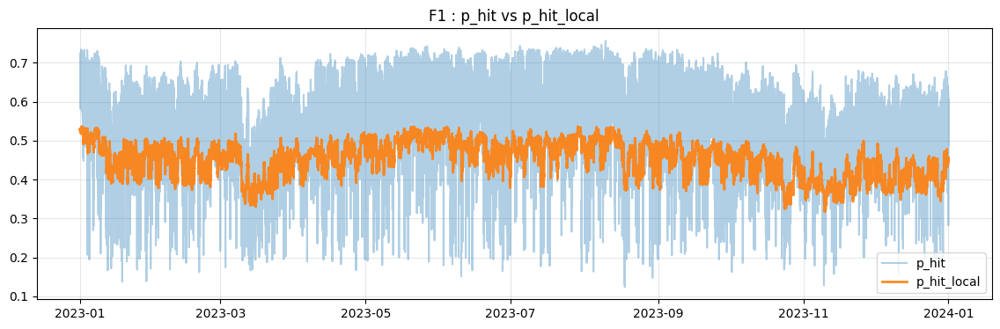

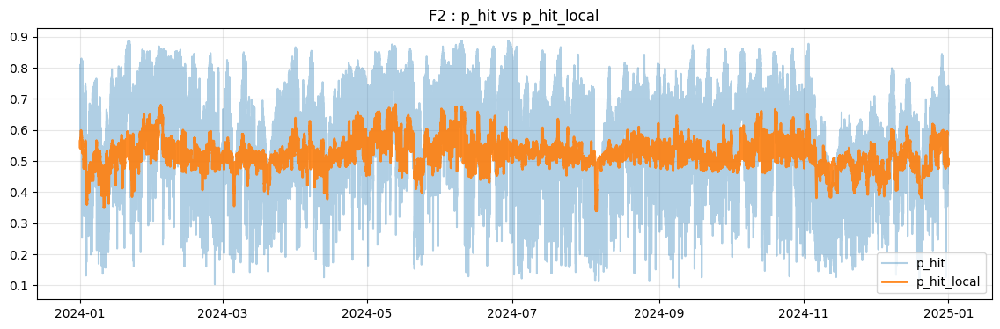

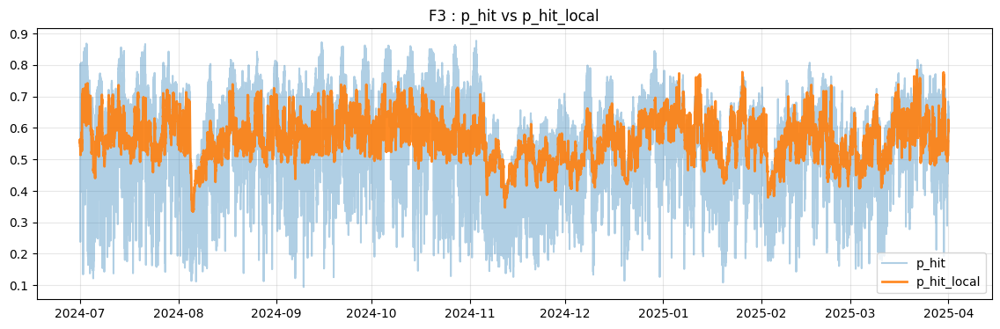

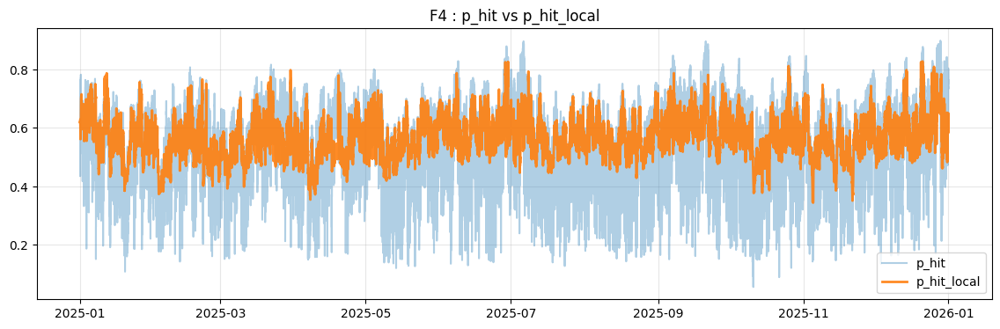

In [ ]:
import matplotlib.pyplot as plt

def plot_time_compare(df, y1, y2, title):
    plt.figure(figsize=(14,4))
    plt.plot(df["t"], df[y1], alpha=0.35, label=y1)
    plt.plot(df["t"], df[y2], alpha=0.9, linewidth=2, label=y2)
    plt.legend()
    plt.title(title)
    plt.grid(alpha=0.3)
    plt.show()

# plot per fold
for f in ["F1","F2","F3","F4"]:
    d = all_test_knn.filter(pl.col("fold")==f).to_pandas()
    plot_time_compare(d, "p_hit", "p_hit_local", f"{f} : p_hit vs p_hit_local")

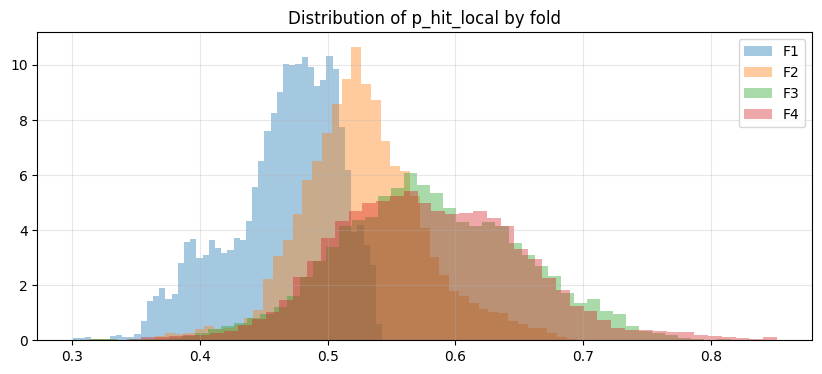

In [ ]:
def plot_hist_by_fold(df, col):
    plt.figure(figsize=(10,4))
    for f in sorted(df["fold"].unique()):
        d = df[df["fold"]==f]
        plt.hist(d[col], bins=50, alpha=0.4, density=True, label=f)
    plt.legend()
    plt.title(f"Distribution of {col} by fold")
    plt.grid(alpha=0.3)
    plt.show()

pdf = all_test_knn.to_pandas()
plot_hist_by_fold(pdf, "p_hit_local")

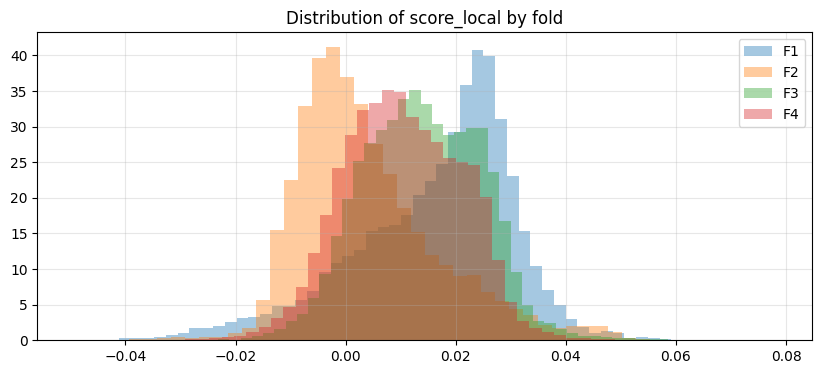

In [ ]:
plot_hist_by_fold(pdf, "score_local")

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

def plot_pca_scatter_phit_local(
    df,
    *,
    fold=None,
    sample=20000,          # กัน plot หนาเกิน
    cmap="viridis",
    vmin=0.45,
    vmax=0.65,
    title_suffix="",
):
    if fold is not None:
        df = df[df["fold"] == fold]

    if sample is not None and len(df) > sample:
        df = df.sample(sample, random_state=42)

    x = df["pc1"].to_numpy()
    y = df["pc2"].to_numpy()
    c = df["p_hit_local"].to_numpy()

    plt.figure(figsize=(6,5))
    sc = plt.scatter(
        x, y,
        c=c,
        s=6,
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
        alpha=0.7,
    )
    plt.colorbar(sc, label="p_hit_local")
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.title(f"PCA scatter colored by p_hit_local {title_suffix}")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

In [ ]:
FOLDS

[{'fold': 'F1',
  'train_start': '2022-01-01',
  'train_end': '2022-12-31',
  'test_start': '2023-01-01',
  'test_end': '2023-12-31'},
 {'fold': 'F2',
  'train_start': '2022-01-01',
  'train_end': '2023-12-31',
  'test_start': '2024-01-01',
  'test_end': '2024-12-31'},
 {'fold': 'F3',
  'train_start': '2022-01-01',
  'train_end': '2024-06-30',
  'test_start': '2024-07-01',
  'test_end': '2025-03-31'},
 {'fold': 'F4',
  'train_start': '2022-01-01',
  'train_end': '2024-12-31',
  'test_start': '2025-01-01',
  'test_end': '2025-12-31'}]

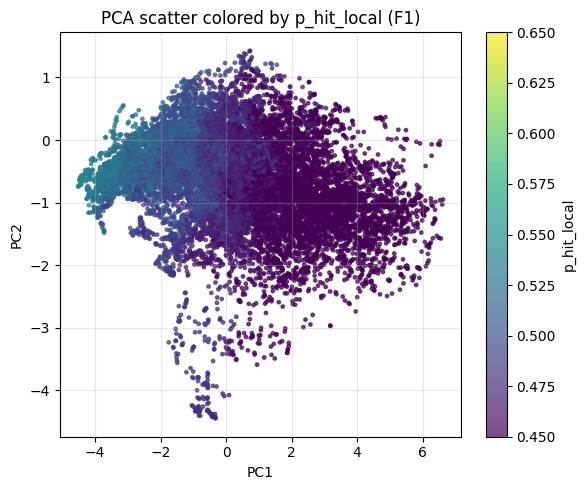

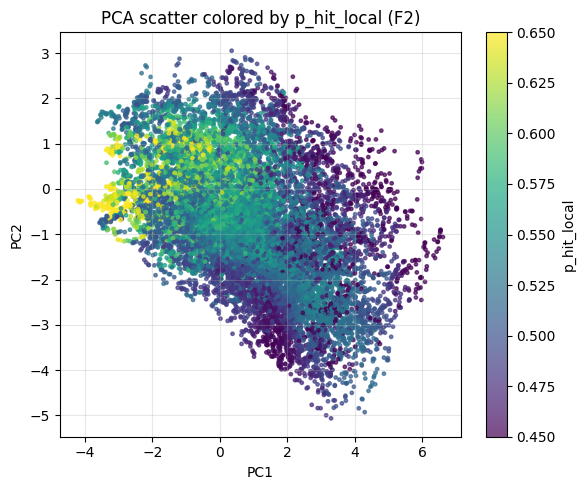

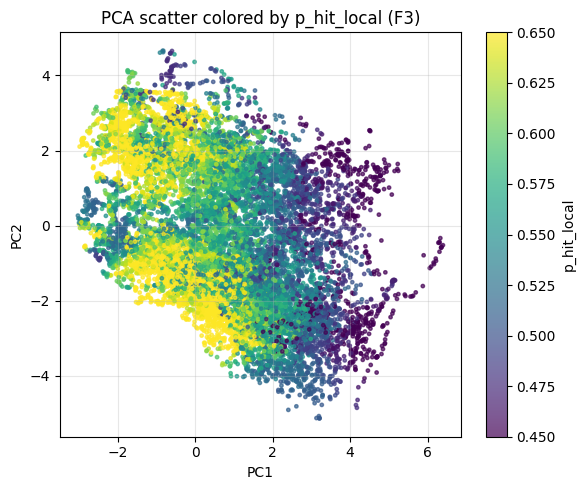

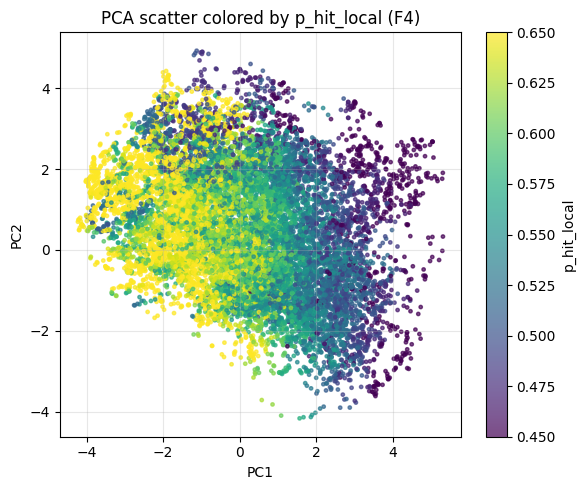

In [ ]:
pdf = all_test_knn.to_pandas()

# plot แยก fold
for f in ["F1","F2","F3","F4"]:
    plot_pca_scatter_phit_local(
        pdf,
        fold=f,
        sample=15000,
        title_suffix=f"({f})"
    )

In [ ]:
pdf

,t,p_hit,score_dir,pc1,pc2,pc3,fold,split,p_hit_local,score_local
0,2023-01-01 00:08:00,0.651318,0.004510,-3.073549,-0.575365,-0.709508,F1,test,0.527476,0.003932
1,2023-01-01 00:17:00,0.640826,0.003102,-3.024303,-0.583732,-0.680021,F1,test,0.526692,0.005393
2,2023-01-01 00:18:00,0.638026,0.008342,-3.014630,-0.571449,-0.688408,F1,test,0.528119,0.005459
3,2023-01-01 00:22:00,0.633543,0.002886,-3.002140,-0.597745,-0.647948,F1,test,0.526435,0.007018
4,2023-01-01 00:23:00,0.627815,0.003025,-3.001431,-0.605850,-0.644031,F1,test,0.526146,0.007283
...,...,...,...,...,...,...,...,...,...,...
552191,2025-12-31 23:17:00,0.751897,0.035650,-1.085909,1.480606,0.614913,F4,test,0.617268,0.003056
552192,2025-12-31 23:18:00,0.754160,0.020433,-1.092654,1.492932,0.616261,F4,test,0.620370,0.003553
552193,2025-12-31 23:19:00,0.764357,-0.055478,-1.107172,1.493902,0.612159,F4,test,0.622083,0.003678
552194,2025-12-31 23:25:00,0.733841,0.045704,-1.130454,1.543502,0.608350,F4,test,0.627802,0.003393


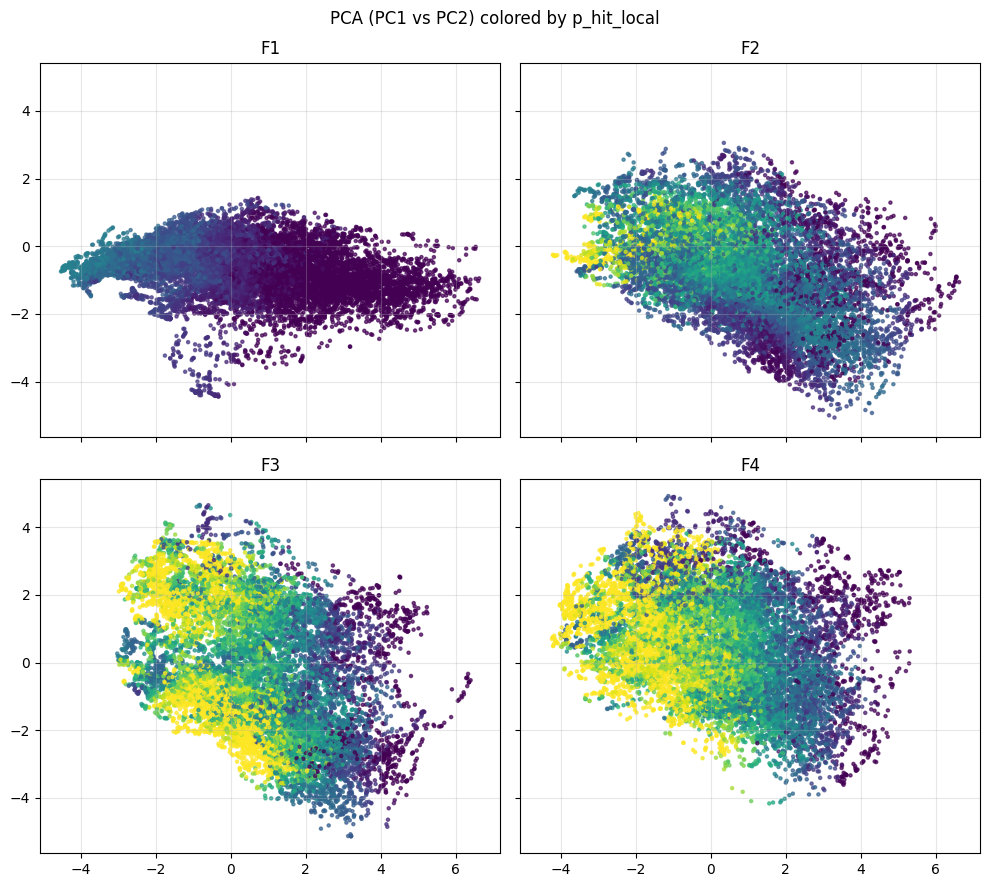

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(10,9), sharex=True, sharey=True)

for ax, f in zip(axes.flat, ["F1","F2","F3","F4"]):
    d = pdf[pdf["fold"] == f]
    if len(d) > 15000:
        d = d.sample(15000, random_state=42)

    sc = ax.scatter(
        d["pc1"], d["pc2"],
        c=d["p_hit_local"],
        s=5,
        cmap="viridis",
        vmin=0.45,
        vmax=0.65,
        alpha=0.7,
    )
    ax.set_title(f)
    ax.grid(alpha=0.3)

# fig.colorbar(sc, ax=axes.ravel().tolist(), label="p_hit_local")
plt.suptitle("PCA (PC1 vs PC2) colored by p_hit_local")
plt.tight_layout()
plt.show()

In [ ]:
pdf

,t,p_hit,score_dir,pc1,pc2,pc3,fold,split,p_hit_local,score_local
0,2023-01-01 00:08:00,0.651318,0.004510,-3.073549,-0.575365,-0.709508,F1,test,0.527476,0.003932
1,2023-01-01 00:17:00,0.640826,0.003102,-3.024303,-0.583732,-0.680021,F1,test,0.526692,0.005393
2,2023-01-01 00:18:00,0.638026,0.008342,-3.014630,-0.571449,-0.688408,F1,test,0.528119,0.005459
3,2023-01-01 00:22:00,0.633543,0.002886,-3.002140,-0.597745,-0.647948,F1,test,0.526435,0.007018
4,2023-01-01 00:23:00,0.627815,0.003025,-3.001431,-0.605850,-0.644031,F1,test,0.526146,0.007283
...,...,...,...,...,...,...,...,...,...,...
552191,2025-12-31 23:17:00,0.751897,0.035650,-1.085909,1.480606,0.614913,F4,test,0.617268,0.003056
552192,2025-12-31 23:18:00,0.754160,0.020433,-1.092654,1.492932,0.616261,F4,test,0.620370,0.003553
552193,2025-12-31 23:19:00,0.764357,-0.055478,-1.107172,1.493902,0.612159,F4,test,0.622083,0.003678
552194,2025-12-31 23:25:00,0.733841,0.045704,-1.130454,1.543502,0.608350,F4,test,0.627802,0.003393


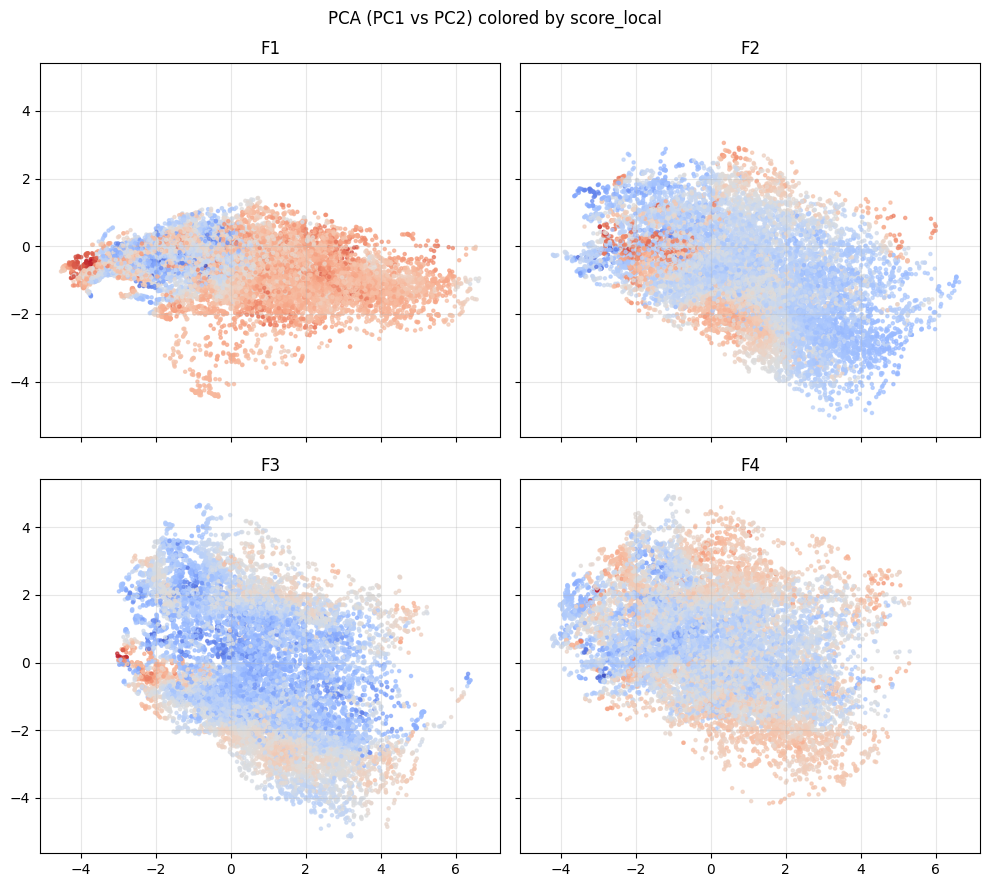

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(10,9), sharex=True, sharey=True)

for ax, f in zip(axes.flat, ["F1","F2","F3","F4"]):
    d = pdf[pdf["fold"] == f]
    if len(d) > 15000:
        d = d.sample(15000, random_state=42)

    sc = ax.scatter(
        d["pc1"], d["pc2"],
        c=d["score_local"],
        s=5,
        cmap="coolwarm",   # แนะนำ diverging สำหรับ score
        alpha=0.7,
    )

    ax.set_title(f)
    ax.grid(alpha=0.3)

# fig.colorbar(sc, ax=axes.ravel().tolist(), label="score_local")
plt.suptitle("PCA (PC1 vs PC2) colored by score_local")
plt.tight_layout()
plt.show()

# R1

In [ ]:
import polars as pl

df = pl.read_parquet(str(data_path("Micro Structure Behavior/df_q_fixed_L_to_Tree.parquet")))

In [ ]:
import math
import numpy as np
import polars as pl
import matplotlib.pyplot as plt

from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA

CFG = dict(
    tcol="t",
    pcol="close",
    state_cols=[
        "active_ms_rank_ema_480",
        "rv_sqrt_q_rank_ema_480",
        "run_mean_q_rank_ema_480",
        "avg_trade_q_rank_ema_480",
    ],
    sig1m_col="rv_sqrt_ema_480",  # หน่วยเดียวกับ return จะดีที่สุด (ex-ante)
    H_min=30,
    k_barrier=1.0,
    lag_sigma=True,

    # kNN manifold regression
    knn_k=200,         # เริ่ม 100–500 แล้วดูความลื่น
    sample_n=200_000,  # subsample ต่อ quarter เพื่อให้เร็ว
    seed=7,
)

In [ ]:
def add_forward_return(df: pl.DataFrame, H_min: int, *, tcol: str, pcol: str) -> pl.DataFrame:
    h = int(H_min)
    return (
        df.sort(tcol)
          .with_columns([(pl.col(pcol).shift(-h) / pl.col(pcol)).log().alias(f"ret_fwd_{H_min}m")])
    )

def add_barrier_hits(df: pl.DataFrame, H_min: int, k: float,
                     *, tcol: str, pcol: str, sig1m_col: str, lag_sigma: bool = True) -> pl.DataFrame:
    h = int(H_min)
    d = df.sort(tcol)

    d = d.with_columns([
        (pl.col(pcol).shift(-1).rolling_max(window_size=h) / pl.col(pcol)).log().alias(f"max_fwd_ret_{H_min}m"),
        (pl.col(pcol).shift(-1).rolling_min(window_size=h) / pl.col(pcol)).log().alias(f"min_fwd_ret_{H_min}m"),
    ])

    sig1m = pl.col(sig1m_col)
    if lag_sigma:
        sig1m = sig1m.shift(1)

    d = d.with_columns([(sig1m * math.sqrt(h)).alias(f"sigma_{H_min}m")])

    d = d.with_columns([
        (pl.col(f"max_fwd_ret_{H_min}m") >=  k * pl.col(f"sigma_{H_min}m")).alias(f"hit_up_{H_min}m"),
        (pl.col(f"min_fwd_ret_{H_min}m") <= -k * pl.col(f"sigma_{H_min}m")).alias(f"hit_dn_{H_min}m"),
        ((pl.col(f"max_fwd_ret_{H_min}m") >= k * pl.col(f"sigma_{H_min}m")) |
         (pl.col(f"min_fwd_ret_{H_min}m") <= -k * pl.col(f"sigma_{H_min}m"))).alias(f"hit_any_{H_min}m"),
    ])
    return d


In [ ]:
def add_quarter_key(df: pl.DataFrame, *, tcol: str) -> pl.DataFrame:
    q = (((pl.col(tcol).dt.month() - 1) // 3) + 1).cast(pl.Int8)
    return df.with_columns([
        (pl.col(tcol).dt.year().cast(pl.Utf8) + pl.lit("-Q") + q.cast(pl.Utf8)).alias("qkey")
    ])

In [ ]:
def prepare_points(df: pl.DataFrame, cfg: dict, qkey: str):
    tcol, pcol = cfg["tcol"], cfg["pcol"]
    state_cols = cfg["state_cols"]
    H_min, k_barrier = cfg["H_min"], cfg["k_barrier"]

    retcol = f"ret_fwd_{H_min}m"
    hitcol = f"hit_any_{H_min}m"

    d = (
        df
        .pipe(add_forward_return, H_min, tcol=tcol, pcol=pcol)
        .pipe(add_barrier_hits, H_min, k_barrier, tcol=tcol, pcol=pcol,
              sig1m_col=cfg["sig1m_col"], lag_sigma=cfg["lag_sigma"])
        .pipe(add_quarter_key, tcol=tcol)
        .filter(pl.col("qkey") == qkey)
        .filter(
            pl.col(retcol).is_not_null() &
            pl.col(hitcol).is_not_null() &
            pl.all_horizontal([pl.col(c).is_not_null() for c in state_cols])
        )
    )

    # subsample ให้เร็ว (random)
    n = d.height
    take_n = min(cfg["sample_n"], n)
    if take_n < n:
        d = d.sample(n=take_n, seed=cfg["seed"], shuffle=True)

    # X: state (4D), y_ret: forward return, y_hit: barrier hit (0/1)
    X = d.select(state_cols).to_numpy()
    y_ret = d.select(retcol).to_numpy().ravel()
    y_hit = d.select(hitcol).cast(pl.Float64).to_numpy().ravel()

    return X, y_ret, y_hit

In [ ]:
def knn_local_expectation(X: np.ndarray, y: np.ndarray, k: int):
    nbrs = NearestNeighbors(n_neighbors=min(k, len(X)), algorithm="auto")
    nbrs.fit(X)
    idx = nbrs.kneighbors(X, return_distance=False)  # (n, k)

    # local mean
    y_hat = y[idx].mean(axis=1)
    return y_hat

In [ ]:
import numpy as np
from sklearn.decomposition import PCA

def pca_stratified_sample(
    X,
    y,
    *,
    pca_model=None,
    n_components=3,
    bins=12,
    max_points=30_000,
    seed=42,
):
    """
    X : (n, d)
    y : (n,) color / outcome
    return: X_sub, y_sub, Z_sub, pca
    """

    rng = np.random.default_rng(seed)

    # 1) PCA
    if pca_model is None:
        pca = PCA(n_components=n_components, random_state=0)
        Z = pca.fit_transform(X)
    else:
        pca = pca_model
        Z = pca.transform(X)

    # 2) bin in PCA space
    edges = [
        np.linspace(Z[:, i].min(), Z[:, i].max(), bins + 1)
        for i in range(n_components)
    ]

    idx_bins = []
    for i in range(n_components):
        idx_bins.append(np.digitize(Z[:, i], edges[i]) - 1)

    cell_id = idx_bins[0]
    for i in range(1, n_components):
        cell_id = cell_id * bins + idx_bins[i]

    # 3) sample per cell
    uniq = np.unique(cell_id)
    per_cell = max(1, max_points // len(uniq))

    keep = []
    for u in uniq:
        ii = np.where(cell_id == u)[0]
        if len(ii) <= per_cell:
            keep.append(ii)
        else:
            keep.append(rng.choice(ii, per_cell, replace=False))

    keep = np.concatenate(keep)

    return X[keep], y[keep], Z[keep], pca

In [ ]:
import plotly.graph_objects as go

def plotly_pca_3d_sampled(
    X,
    color,
    *,
    title="",
    color_title="value",
    max_points=30_000,
    bins=12,
    point_size=3,
    opacity=0.8,
    pca_model=None,
    cmin=None,
    cmax=None
):
    # --- stratified sample ---
    Xs, ys, Zs, pca = pca_stratified_sample(
        X, color,
        pca_model=pca_model,
        bins=bins,
        max_points=max_points,
    )

    fig = go.Figure(
        data=[
            go.Scatter3d(
                x=Zs[:, 0],
                y=Zs[:, 1],
                z=Zs[:, 2],
                mode="markers",
                marker=dict(
                    size=point_size,
                    color=ys,
                    colorscale="Viridis",
                    cmin=cmin,
                    cmax=cmax,
                    opacity=opacity,
                    colorbar=dict(title=color_title),
                ),
            )
        ]
    )

    fig.update_layout(
        title=title + f" (n={len(Zs):,})",
        scene=dict(
            xaxis_title="PC1",
            yaxis_title="PC2",
            zaxis_title="PC3",
        ),
        margin=dict(l=0, r=0, b=0, t=40),
    )

    fig.show()
    return pca

In [ ]:
# เลือก quarter ที่อยากดู
qkey = "2025-Q4"   # แก้เป็นของคุณ

X, y_ret, y_hit = prepare_points(df, CFG, qkey=qkey)

In [ ]:
mean_ret_hat = knn_local_expectation(X, y_ret, k=CFG["knn_k"])
hit_rate_hat = knn_local_expectation(X, y_hit, k=CFG["knn_k"])

In [ ]:
c = mean_ret_hat
print("min/1%/50%/99%/max =", np.min(c), np.quantile(c,0.01), np.median(c), np.quantile(c,0.99), np.max(c))
print("std =", np.std(c))

min/1%/50%/99%/max = -0.01604081266021749 -0.005217912887815512 3.299255889504006e-06 0.005031508855977051 0.012575324166956971
std = 0.0018206548840148393


In [ ]:
def clip_symmetric(c, q=0.01):
    lo, hi = np.quantile(c, q), np.quantile(c, 1-q)
    m = max(abs(lo), abs(hi))
    return -m, m

cmin, cmax = clip_symmetric(hit_rate_hat, q=0.01)

In [ ]:
for k in [50, 100, 200]:
    mh = knn_local_expectation(X, y_ret, k=k)
    print(k, np.std(mh), np.quantile(mh,0.01), np.quantile(mh,0.99))

50 0.003388669160849323 -0.010482725304283102 0.009113164498385286
100 0.002471388521548294 -0.007548915721225909 0.006528109594391592
200 0.0018206548840148393 -0.005217912887815512 0.005031508855977051


In [ ]:
pca = plotly_pca_3d_sampled(
    X,
    mean_ret_hat,
    title="2025-Q4 | mean_ret_hat manifold",
    color_title="mean_ret_hat",
    max_points=25_000,   # ปลอดภัย
    bins=12,
    cmin=cmin,
    cmax=cmax
)

In [ ]:
pca = plotly_pca_3d_sampled(
    X,
    hit_rate_hat,
    title="2025-Q4 | hit_rate_hat manifold",
    color_title="hit_rate_hat",
    max_points=25_000,   # ปลอดภัย
    bins=12,
)